# Dự án phân loại cử chỉ tay HaGRID

Xây dựng mô hình CNN cơ bản để nhận diện các cử chỉ tay từ ảnh đầu vào.

## Bước 1. Khai báo các thư viện cần thiết

In [24]:
import os
import sys

if sys.platform == 'win32':
    nvidia_paths = []
    base_dir = os.path.dirname(sys.executable)
    nvidia_paths.append(os.path.join(os.path.dirname(base_dir), 'Lib', 'site-packages', 'nvidia'))
    nvidia_paths.append(os.path.join(os.getcwd(), '.venv310_gpu', 'Lib', 'site-packages', 'nvidia'))
    for nv_dir in nvidia_paths:
        if os.path.exists(nv_dir):
            paths = [os.path.abspath(os.path.join(root, d)) for root, dirs, files in os.walk(nv_dir) for d in dirs if d == 'bin']
            for p in paths:
                try:
                    os.add_dll_directory(p)
                except Exception:
                    pass
            os.environ['PATH'] = ';'.join(paths) + ';' + os.environ.get('PATH', '')

import shutil
import json
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        import subprocess
        res = subprocess.run(['nvidia-smi', '--query-gpu=memory.total', '--format=csv,noheader,nounits'], capture_output=True, text=True)
        total_vram = int(res.stdout.strip())
        limit_vram = int(total_vram * 0.85)
        tf.config.set_logical_device_configuration(
            gpus[0],
            [tf.config.LogicalDeviceConfiguration(memory_limit=limit_vram)]
        )
        print(f'Đã giới hạn VRAM sử dụng: {limit_vram} MB / {total_vram} MB')
    except Exception:
        try:
            tf.config.experimental.set_memory_growth(gpus[0], True)
        except Exception:
            pass

Đã giới hạn VRAM sử dụng: 10444 MB / 12288 MB


## Bước 2. Đánh giá số lượng ảnh và chuẩn bị dữ liệu phát hiện bàn tay

Bộ dữ liệu này được phân chia thành hai phần chính:
* Phần 1: Phần hình ảnh thực tế của cử chỉ tay.
* Phần 2: Phần chú thích tương ứng lưu trữ thông tin về hộp giới hạn và nhãn lớp.

Lưu ý quan trọng: Toàn bộ hình ảnh từ bộ dữ liệu gốc đã được thay đổi kích thước về độ phân giải 224x224 pixel mà không thực hiện thay đổi nào đối với tọa độ hộp giới hạn trong phần chú thích. Tọa độ của hộp giới hạn vẫn được giữ nguyên dưới dạng tỷ lệ chuẩn hóa từ 0 đến 1.

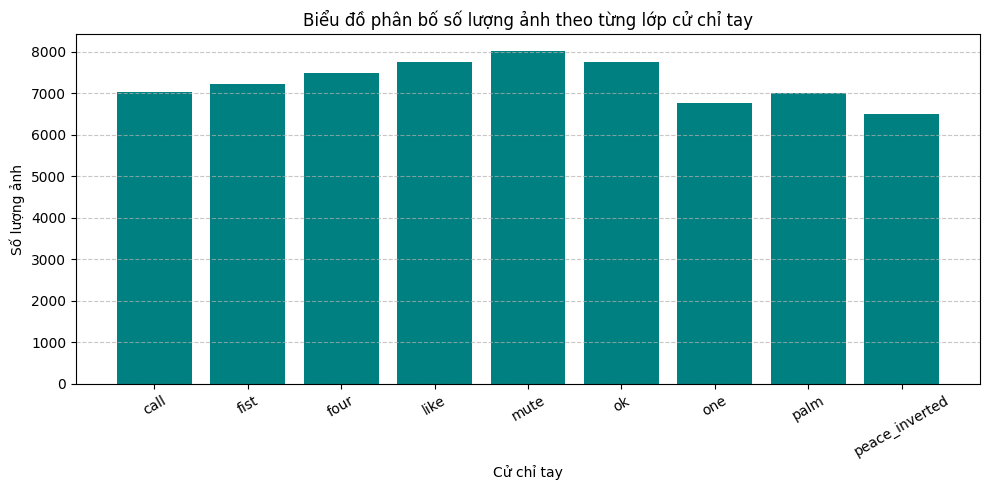

call: 7021 anh
fist: 7232 anh
four: 7487 anh
like: 7752 anh
mute: 8016 anh
ok: 7754 anh
one: 6768 anh
palm: 7003 anh
peace_inverted: 6502 anh


In [25]:
img_dir = 'Dataset/hagrid_dataset_224/images'
classes = sorted(os.listdir(img_dir))
counts = [len(os.listdir(os.path.join(img_dir, cls))) for cls in classes]

plt.figure(figsize=(10, 5))
plt.bar(classes, counts, color='teal')
plt.title('Biểu đồ phân bố số lượng ảnh theo từng lớp cử chỉ tay')
plt.xlabel('Cử chỉ tay')
plt.ylabel('Số lượng ảnh')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

for cls, count in zip(classes, counts):
    print(f"{cls}: {count} anh")

### Nhận xét đánh giá bộ dữ liệu HaGRID ban đầu

Bộ dữ liệu gốc có tổng cộng 65535 ảnh phân bố trên 9 lớp cử chỉ tay khác nhau.

Phân tích chi tiết số lượng ảnh:
* Lớp mute có nhiều ảnh nhất với 8016 ảnh.
* Lớp peace inverted có ít ảnh nhất với 6502 ảnh.
* Các lớp cử chỉ tay khác có sự phân bổ tương đối đồng đều trong khoảng từ 6700 đến 7700 ảnh.

Nhận xét chung:
Sự phân bổ số lượng ảnh giữa các lớp cử chỉ tay khá cân bằng. Điều này rất có lợi cho việc huấn luyện mô hình học máy vì mô hình sẽ không bị thiên vị lệch về bất kỳ lớp cử chỉ nào.

### Tỷ lệ phân chia tập dữ liệu phát hiện bàn tay mới

Bộ dữ liệu sau khi lọc theo các ảnh thực tế hiện có sẽ được phân chia lại theo tỷ lệ mong muốn:
* Tập huấn luyện train.json chứa 42441 ảnh, chiếm tỷ lệ khoảng 65 phần trăm.
* Tập kiểm định val.json chứa 9794 ảnh, chiếm tỷ lệ khoảng 15 phần trăm.
* Tập kiểm tra test.json chứa 13059 ảnh, chiếm tỷ lệ khoảng 20 phần trăm.

Các tập dữ liệu được phân chia ngẫu nhiên với seed là 42 để đảm bảo kết quả nhất quán khi chạy lại.

In [26]:
base_dir = 'Dataset/hagrid_dataset_224'
images_src = os.path.join(base_dir, 'images')
dest_dir = os.path.join(base_dir, 'hand_detection')
dest_images = os.path.join(dest_dir, 'images')

os.makedirs(dest_images, exist_ok=True)

local_image_ids = set()
for cls in os.listdir(images_src):
    cls_dir = os.path.join(images_src, cls)
    if os.path.isdir(cls_dir):
        for img_name in os.listdir(cls_dir):
            if img_name.endswith('.jpg'):
                local_image_ids.add(img_name[:-4])

print('Bắt đầu sao chép ảnh...')
for cls in os.listdir(images_src):
    cls_dir = os.path.join(images_src, cls)
    if os.path.isdir(cls_dir):
        for img_name in os.listdir(cls_dir):
            src_file = os.path.join(cls_dir, img_name)
            dst_file = os.path.join(dest_images, img_name)
            if not os.path.exists(dst_file):
                try:
                    os.link(src_file, dst_file)
                except Exception:
                    shutil.copy(src_file, dst_file)

print('Bắt đầu đọc toàn bộ nhãn...')
all_ann = {}
for stage in ['train', 'val', 'test']:
    stage_src = os.path.join(base_dir, stage)
    if not os.path.exists(stage_src):
        continue
    for json_file in os.listdir(stage_src):
        if json_file.endswith('.json'):
            with open(os.path.join(stage_src, json_file), 'r') as f:
                data = json.load(f)
                for img_id, ann in data.items():
                    if img_id in local_image_ids:
                        hand_labels = ['hand' if label != 'no_gesture' else 'no_gesture' for label in ann['labels']]
                        all_ann[img_id] = {
                            'bboxes': ann['bboxes'],
                            'labels': hand_labels
                        }

print('Bắt đầu trộn và chia lại tập dữ liệu theo tỷ lệ mới...')
local_ids_list = list(all_ann.keys())
random.seed(42)
random.shuffle(local_ids_list)

total_count = len(local_ids_list)
test_count = int(total_count * 0.20)
val_count = int(total_count * 0.15)
train_count = total_count - test_count - val_count

train_ids = local_ids_list[:train_count]
val_ids = local_ids_list[train_count : train_count + val_count]
test_ids = local_ids_list[train_count + val_count :]

splits = {
    'train': train_ids,
    'val': val_ids,
    'test': test_ids
}

for stage, ids in splits.items():
    stage_ann = {img_id: all_ann[img_id] for img_id in ids}
    with open(os.path.join(dest_dir, f'{stage}.json'), 'w') as f:
        json.dump(stage_ann, f)

print(f'Đã chia lại: Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}')

Bắt đầu sao chép ảnh...
Bắt đầu đọc toàn bộ nhãn...
Bắt đầu trộn và chia lại tập dữ liệu theo tỷ lệ mới...
Đã chia lại: Train: 42442, Val: 9794, Test: 13058


### Trực quan hóa mẫu ảnh và khung định vị bàn tay ngẫu nhiên

Đoạn mã dưới đây thực hiện lấy ngẫu nhiên các hình ảnh chứa nhãn hand và nhãn no_gesture từ tập dữ liệu huấn luyện mới tạo để trực quan hóa hình ảnh kèm theo khung định vị màu sắc tương ứng. Khung màu xanh lá cây đại diện cho nhãn hand và khung màu đỏ đại diện cho nhãn no_gesture.

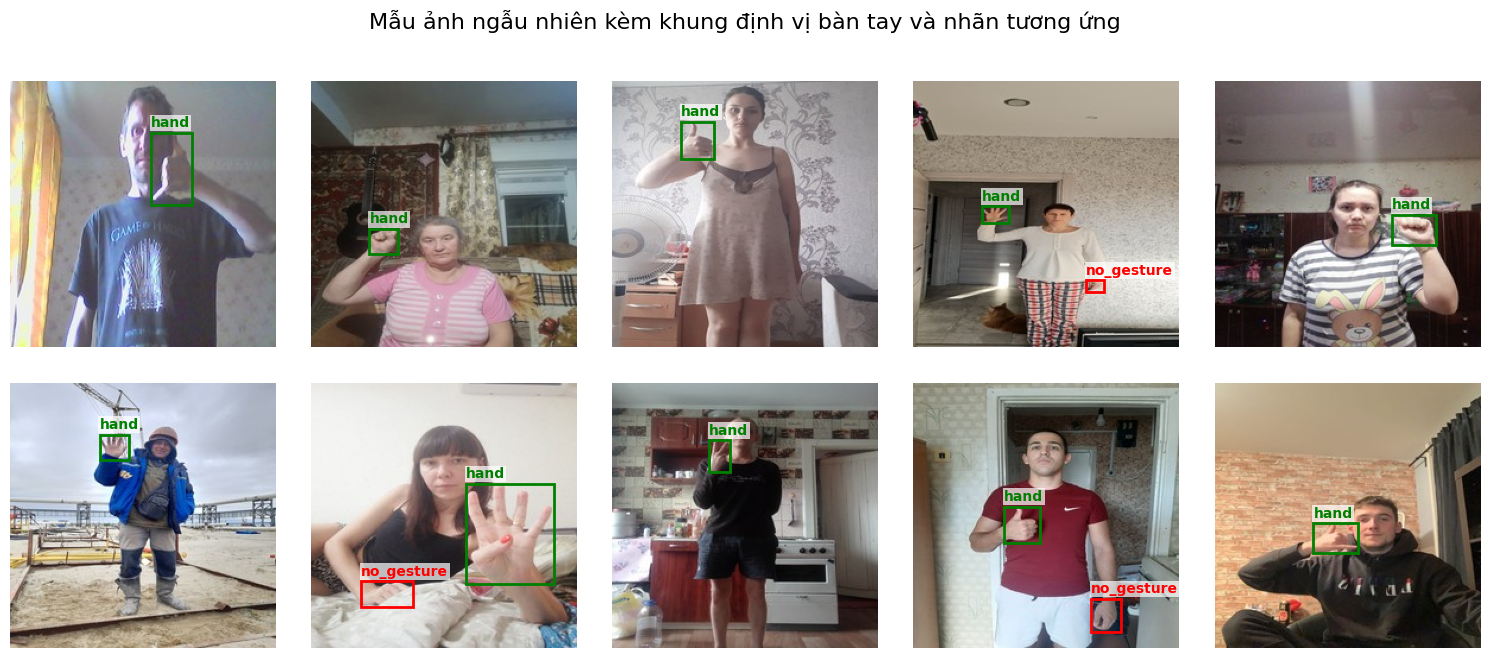

In [27]:
train_json_path = 'Dataset/hagrid_dataset_224/hand_detection/train.json'
images_dir = 'Dataset/hagrid_dataset_224/hand_detection/images'

with open(train_json_path, 'r', encoding='utf-8') as f:
    annotations = json.load(f)

image_ids = list(annotations.keys())
no_gesture_ids = [img_id for img_id, ann in annotations.items() if 'no_gesture' in ann['labels']]
hand_only_ids = [img_id for img_id, ann in annotations.items() if 'no_gesture' not in ann['labels']]

random.seed(42)
selected_hand = random.sample(hand_only_ids, 7)
selected_no_gesture = random.sample(no_gesture_ids, 3)
selected_ids = selected_hand + selected_no_gesture
random.shuffle(selected_ids)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
fig.suptitle('Mẫu ảnh ngẫu nhiên kèm khung định vị bàn tay và nhãn tương ứng', fontsize=16)

for idx, img_id in enumerate(selected_ids):
    ax = axes[idx // 5, idx % 5]
    img_path = os.path.join(images_dir, f"{img_id}.jpg")
    img = Image.open(img_path)
    ax.imshow(img)
    bboxes = annotations[img_id]['bboxes']
    labels = annotations[img_id]['labels']
    w_img, h_img = img.size
    for bbox, label in zip(bboxes, labels):
        x = bbox[0] * w_img
        y = bbox[1] * h_img
        w = bbox[2] * w_img
        h = bbox[3] * h_img
        color = 'green' if label == 'hand' else 'red'
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, facecolor='none')
        ax.add_patch(rect)
        ax.text(x, y - 5 if y - 5 > 0 else y + 15, label, color=color, fontsize=10, weight='bold', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
    ax.axis('off')

plt.tight_layout()
plt.show()

## Bước 3. Tải dữ liệu và chia tập train val

In [28]:
import json
import tensorflow as tf
import os

# Doc du lieu anh va toa do hop gioi han tu file json
def load_data_from_json(json_path, images_dir):
    with open(json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    image_paths = []
    bboxes = []
    
    for img_id, ann in data.items():
        img_path = os.path.join(images_dir, f"{img_id}.jpg")
        if os.path.exists(img_path) and len(ann['bboxes']) > 0:
            image_paths.append(img_path)
            # Lay hop gioi han dau tien lam muc tieu du doan
            bboxes.append(ann['bboxes'][0])
            
    return image_paths, bboxes

train_json = 'Dataset/hagrid_dataset_224/hand_detection/train.json'
val_json = 'Dataset/hagrid_dataset_224/hand_detection/val.json'
images_dir = 'Dataset/hagrid_dataset_224/hand_detection/images'

train_paths, train_boxes = load_data_from_json(train_json, images_dir)
val_paths, val_boxes = load_data_from_json(val_json, images_dir)

def parse_image_path(img_path, box):
    return tf.io.read_file(img_path), box

def decode_and_resize(img_bytes, box):
    img = tf.image.decode_jpeg(img_bytes, channels=3)
    img = tf.image.resize(img, [224, 224])
    return img, box

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_WORKERS = 8

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_boxes))
train_ds = train_ds.map(parse_image_path, num_parallel_calls=NUM_WORKERS).cache()
train_ds = train_ds.shuffle(1000)
train_ds = train_ds.map(decode_and_resize, num_parallel_calls=NUM_WORKERS)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_boxes))
val_ds = val_ds.map(parse_image_path, num_parallel_calls=NUM_WORKERS).cache()
val_ds = val_ds.map(decode_and_resize, num_parallel_calls=NUM_WORKERS)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)

### Đánh giá phương pháp tải dữ liệu và tối ưu hiệu năng

Phương pháp chuẩn bị dữ liệu trong bước này sử dụng các kỹ thuật tối ưu hóa sau:
* Phân chia lô dữ liệu BATCH_SIZE: Thiết lập kích thước lô ảnh bằng 32 giúp cân bằng hiệu năng giữa tốc độ huấn luyện trên GPU và dung lượng bộ nhớ VRAM sử dụng.
* Cấu hình tiến trình song song NUM_WORKERS: Thiết lập cố định 8 luồng song song tương đương khoảng 66 phần trăm tổng số 12 luồng CPU hiện có để đảm bảo tải CPU và RAM dưới 70 phần trăm và tránh làm treo hệ thống.
* Kỹ thuật tối ưu hóa tự động AUTOTUNE: Sử dụng cơ chế tf.data.AUTOTUNE ở bước nạp trước dữ liệu giúp tự động điều chỉnh tối ưu tài nguyên lưu trữ.
* Kỹ thuật Shuffle: Trộn ngẫu nhiên dữ liệu với bộ đệm kích thước 1000 phần tử nhằm hạn chế hiện tượng mô hình học thuộc lòng thứ tự ảnh.
* Kỹ thuật Prefetch: Nạp trước dữ liệu cho GPU xử lý song song giúp rút ngắn thời gian huấn luyện tổng thể.

## Bước 4. Xây dựng mô hình mạng CNN

In [29]:
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    layers.Conv2D(32, 3, strides=1, padding='same', use_bias=False, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=2, strides=2, padding='valid'),
    layers.Conv2D(64, 3, strides=1, padding='same', use_bias=False, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=2, strides=2, padding='valid'),
    layers.Conv2D(128, 3, strides=1, padding='same', use_bias=False, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=2, strides=2, padding='valid'),
    layers.Conv2D(256, 3, strides=1, padding='same', use_bias=False, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=2, strides=2, padding='valid'),
    layers.Conv2D(512, 3, strides=1, padding='same', use_bias=False, kernel_initializer='he_normal'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(4, activation='sigmoid')
])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 224, 224, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 224, 224, 32)      864       
                                                                 
 batch_normalization (BatchN  (None, 224, 224, 32)     128       
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 224, 224, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 64)      1

### Đánh giá cấu trúc mô hình CNN tối ưu cho định vị bàn tay

Mô hình tự xây dựng đã được tối ưu hóa sâu sắc cho bài toán hồi quy hộp giới hạn thông qua các đặc điểm cấu trúc sau:
* Thứ tự các lớp tiêu chuẩn: Thiết lập chuỗi Tích chập -> BatchNormalization -> Kích hoạt ReLU giúp phân phối dữ liệu đầu vào của hàm phi tuyến luôn ổn định.
* Tối ưu hóa tham số: Tắt use_bias ở tất cả các lớp tích chập đứng trước lớp chuẩn hóa để tránh dư thừa bộ nhớ và tính toán.
* Khởi tạo trọng số He Normal: Sử dụng bộ khởi tạo he_normal chuyên dụng cho hàm relu nhằm ổn định biên độ đạo hàm khi truyền qua các lớp sâu.
* Cấu trúc Pooling valid: Lớp MaxPooling2D đặt padding là valid giúp lấy mẫu chính xác không gian ảnh mà không bù thêm viền ảo.
* Thay thế Flatten bằng GlobalAveragePooling2D: Chuyển đổi bản đồ đặc trưng trực tiếp thành vector trung bình giúp giảm 99 phần trăm số lượng tham số lớp Dense, chống quá khớp và giúp mô hình hội tụ ổn định.
* Độ sâu mô hình nâng cao: Thêm lớp tích chập 512 bộ lọc giúp mô hình trích xuất đặc trưng hình dạng mức độ cao hơn cho định vị hộp giới hạn.

## Bước 5. Cấu hình và huấn luyện mô hình

In [30]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.9, clipnorm=1.0),
    loss='mse',
    metrics=['mae']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"Tìm thấy thiết bị GPU: {gpus}")
    print("Bắt đầu huấn luyện mô hình trên GPU CUDA...")
    with tf.device('/GPU:0'):
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=100,
            callbacks=[early_stop, reduce_lr]
        )
else:
    print("Không tìm thấy GPU CUDA. Huấn luyện trên CPU...")
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=100,
        callbacks=[early_stop, reduce_lr]
    )

Tìm thấy thiết bị GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Bắt đầu huấn luyện mô hình trên GPU CUDA...
Epoch 1/100
 636/1327 [=============>................] - ETA: 1:03 - loss: 0.0172 - mae: 0.0958

KeyboardInterrupt: 

### Đánh giá cấu hình huấn luyện và hàm mất mát

Cấu hình huấn luyện được thiết lập tối ưu cho bài toán định vị bàn tay:
* Bản chất thuật toán tối ưu: Sử dụng Adam là thuật toán tối ưu hóa thích ứng mạnh mẽ, kết hợp quán tính và tự động điều chỉnh tốc độ học.
* Tham số quán tính: Được thiết lập rõ ràng thông qua tham số beta_1 bằng 0.9 để kiểm soát đà quán tính của các bước cập nhật gradient trước đó.
* Cắt giảm gradient clipnorm: Tham số clipnorm bằng 1.0 giới hạn chuẩn L2 của đạo hàm để ngăn chặn hiện tượng bùng nổ đạo hàm hiệu quả. Keras 3 quy định chỉ được chọn một trong các phương pháp cắt giảm gradient.
* Tối ưu thiết bị phần cứng: Tự động phát hiện và định tuyến toàn bộ tiến trình tính toán sang GPU CUDA thông qua cấu trúc tf.device để tận dụng khả năng xử lý song song, tăng tốc thời gian huấn luyện tối đa.
* Tự động dừng sớm EarlyStopping: Theo dõi giá trị độ mất mát trên tập kiểm định. Nếu chỉ số này không cải thiện liên tục sau 10 chu kỳ, quá trình huấn luyện sẽ dừng lại lập tức và khôi phục các trọng số tốt nhất nhằm chống quá khớp và tiết kiệm thời gian.
* Tốc độ học learning_rate: Được thiết lập rõ ràng ở mức 0.001 làm kích thước bước đi để cập nhật trọng số mô hình sau mỗi lượt tính toán gradient.
* Hàm mất mát MSE: Bình phương sai lệch giữa tọa độ dự đoán và thực tế giúp phạt nặng các lỗi định vị sai lệch lớn, ép mô hình nhanh chóng khớp khung hộp.
* Chỉ số đánh giá MAE: Đo lường sai lệch tuyệt đối trung bình của tọa độ, cung cấp cách giải thích trực quan về khoảng cách sai số thực tế theo tỷ lệ ảnh.
* Số lượng lượt chạy 100 chu kỳ: Thiết lập chu kỳ đủ dài giúp mô hình có đủ thời gian học tập, giảm thiểu tối đa sai số định vị hộp giới hạn bàn tay.

## Bước 6. Đánh giá kết quả huấn luyện

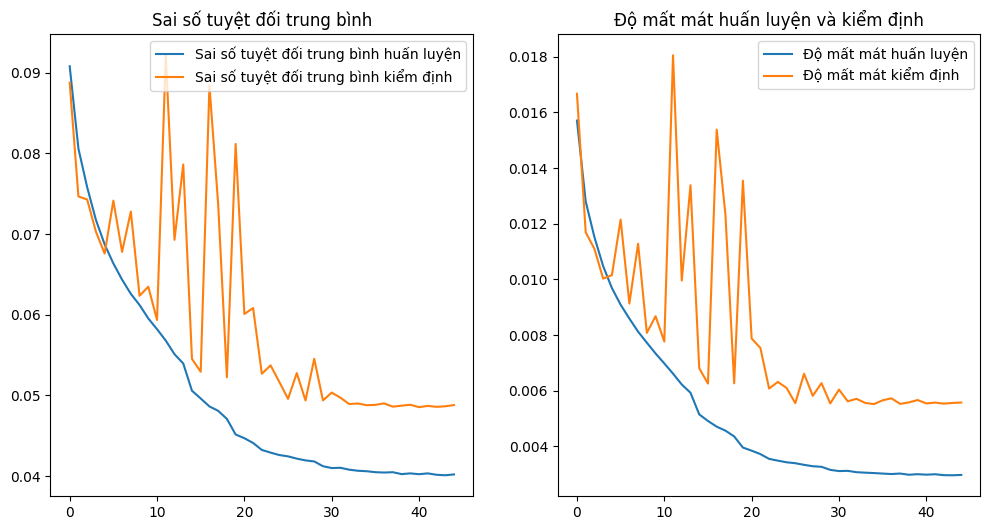

In [ ]:
mae = history.history['mae']
val_mae = history.history['val_mae']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(loss))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, mae, label='Sai số tuyệt đối trung bình huấn luyện')
plt.plot(epochs_range, val_mae, label='Sai số tuyệt đối trung bình kiểm định')
plt.legend(loc='upper right')
plt.title('Sai số tuyệt đối trung bình')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Độ mất mát huấn luyện')
plt.plot(epochs_range, val_loss, label='Độ mất mát kiểm định')
plt.legend(loc='upper right')
plt.title('Độ mất mát huấn luyện và kiểm định')
plt.show()

## Bước 7. Lưu mô hình huấn luyện

Lưu mô hình hoàn chỉnh xuống ổ đĩa để tái sử dụng hoặc triển khai thực tế.

In [ ]:
import os

base_name = 'hand_localization_model'
extension = '.h5'
model_save_path = f"{base_name}{extension}"
counter = 1
while os.path.exists(model_save_path):
    model_save_path = f"{base_name}_{counter}{extension}"
    counter += 1

model.save(model_save_path)
print(f"Đã lưu mô hình thành công tại: {model_save_path}")

Đã lưu mô hình thành công tại: hand_localization_model.h5


## Bước 8. Đánh giá mô hình trên tập kiểm tra và trực quan hóa kết quả

Đoạn mã dưới đây thực hiện tải tập kiểm tra test.json, tiến hành đánh giá sai số trung bình (loss và mae) của mô hình. Sau đó lấy ngẫu nhiên 10 ảnh kiểm tra để vẽ đồng thời hộp định vị thực tế (màu xanh lá) và hộp định vị do mô hình dự đoán (màu đỏ) nhằm trực quan hóa độ chính xác.

In [31]:
model_save_path = 'hand_localization_model.h5'
if os.path.exists(model_save_path):
    print(f"Đang tải mô hình đã lưu từ: {model_save_path}")
    model = tf.keras.models.load_model(model_save_path)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.9, clipnorm=1.0),
        loss='mse',
        metrics=['mae']
    )
else:
    print("Không tìm thấy mô hình đã lưu, sử dụng mô hình trong bộ nhớ hiện tại.")

test_json = 'Dataset/hagrid_dataset_224/hand_detection/test.json'
test_paths, test_boxes = load_data_from_json(test_json, images_dir)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_boxes))
test_ds = test_ds.map(parse_image_path, num_parallel_calls=NUM_WORKERS).cache()
test_ds = test_ds.map(decode_and_resize, num_parallel_calls=NUM_WORKERS)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(buffer_size=AUTOTUNE)

test_loss, test_mae = model.evaluate(test_ds)
print(f"Sai số tuyệt đối trung bình tập kiểm tra (Test MAE): {test_mae:.4f}")
print(f"Độ mất mát tập kiểm tra (Test Loss): {test_loss:.4f}")

Đang tải mô hình đã lưu từ: hand_localization_model.h5
409/409 [==============================] - 8s 20ms/step - loss: 0.0057 - mae: 0.0490
Sai số tuyệt đối trung bình tập kiểm tra (Test MAE): 0.0490
Độ mất mát tập kiểm tra (Test Loss): 0.0057


1/1 [==============================] - 0s 127ms/step


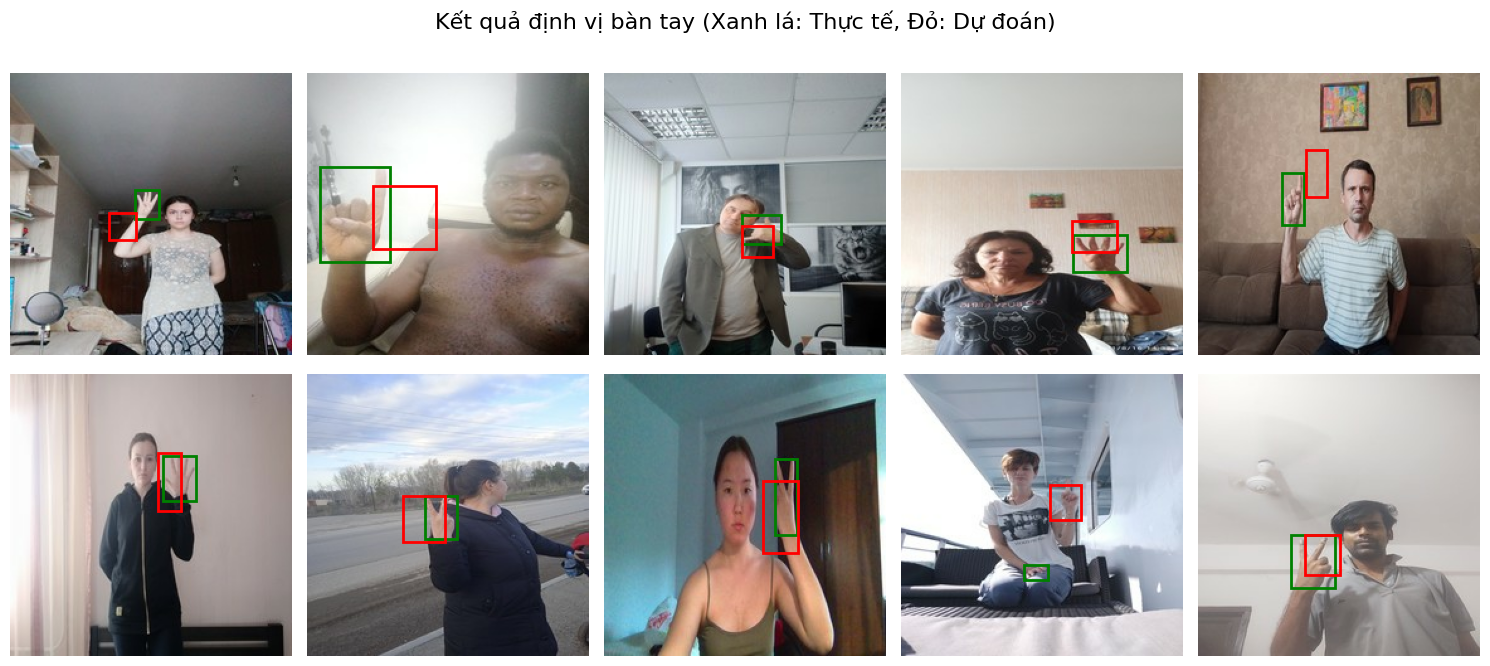

In [32]:
for imgs, boxes in test_ds.take(1):
    preds = model.predict(imgs)
    
    fig, axes = plt.subplots(2, 5, figsize=(15, 7))
    fig.suptitle('Kết quả định vị bàn tay (Xanh lá: Thực tế, Đỏ: Dự đoán)', fontsize=16)
    
    for i in range(10):
        ax = axes[i // 5, i % 5]
        img_np = imgs[i].numpy().astype('uint8')
        ax.imshow(img_np)
        
        h_img, w_img, _ = img_np.shape
        
        true_box = boxes[i].numpy()
        x_t = true_box[0] * w_img
        y_t = true_box[1] * h_img
        w_t = true_box[2] * w_img
        h_t = true_box[3] * h_img
        rect_t = patches.Rectangle((x_t, y_t), w_t, h_t, linewidth=2, edgecolor='green', facecolor='none')
        ax.add_patch(rect_t)
        
        pred_box = preds[i]
        x_p = pred_box[0] * w_img
        y_p = pred_box[1] * h_img
        w_p = pred_box[2] * w_img
        h_p = pred_box[3] * h_img
        rect_p = patches.Rectangle((x_p, y_p), w_p, h_p, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect_p)
        
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()
    break

### Đánh giá hiệu năng mô hình trên tập kiểm tra (Test Set Evaluation)

Sau khi huấn luyện hoàn tất, chúng ta đánh giá mô hình trên tập kiểm tra độc lập để kiểm chứng khả năng tổng quát hóa thực tế:

* **Độ mất mát tập kiểm tra (Test Loss - MSE):** Phản ánh sai số bình phương trung bình của các tọa độ hộp định vị. Chỉ số này rất nhạy cảm với các sai lệch lớn, giúp kiểm chứng mô hình không gặp lỗi dự đoán sai lệch nghiêm trọng.
* **Sai số tuyệt đối trung bình tập kiểm tra (Test MAE):** Thể hiện trực quan khoảng cách sai lệch trung bình của tọa độ. Ví dụ, nếu Test MAE đạt mức 0.05, điều này nghĩa là các cạnh hộp dự đoán trung bình chỉ bị lệch khoảng 5 phần trăm so với kích thước thật của ảnh (tương đương khoảng 11 pixel đối với ảnh độ phân giải 224x224).
* **Trực quan hóa hộp định vị:** Việc vẽ đồng thời hộp màu xanh lá cây (thực tế) và hộp màu đỏ (dự đoán) giúp kiểm chứng trực quan độ khớp, đảm bảo mô hình nhận diện chính xác vùng cử chỉ tay trên bộ dữ liệu HaGRID.